In [ ]:
!pip install pytorch-forecasting pytorch-lightning lightning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.1/403.1 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.4 MB/s eta 0:00:00


In [ ]:
# # dummy_module.py
# # Standalone — import this into ardl, svar, tvar scripts

# import pandas as pd
# import numpy as np
# import statsmodels.api as sm
# import warnings
# warnings.filterwarnings('ignore')


# def create_event_dummies(df_index):
#     """
#     Creates period and point dummies for known shock events.
#     Use corrected wider windows — especially for COVID and Trade War.
#     df_index: DatetimeIndex of your dataset
#     """
#     dummies = pd.DataFrame(index=df_index)

#     # ── Point dummies: genuine single-month instantaneous shocks ──────────────
#     point_events = {
#         'D_Demon'       : '2016-11',   # Demonetization — overnight policy
#         'D_GFC_Peak'    : '2008-10',   # Lehman collapse month
#         'D_COVID_Crash' : '2020-03',   # Single worst crash month
#         'D_Ukraine_Hit' : '2022-02',   # Invasion announcement month
#     }
#     for name, month in point_events.items():
#         dummies[name] = 0
#         mask = df_index.to_period('M').astype(str) == month
#         dummies.loc[mask, name] = 1

#     # ── Period dummies: sustained shock episodes ───────────────────────────────
#     period_events = {
#         'D_GFC'        : ('2008-06', '2009-06'),   # Full GFC + trough
#         'D_EuroDebt'   : ('2011-07', '2012-07'),   # Eurozone crisis
#         'D_TaperTant'  : ('2013-05', '2013-08'),   # Fed taper tantrum
#         'D_ChinaSlump' : ('2015-06', '2016-02'),   # China slowdown + INR pressure
#         'D_TradeWar'   : ('2018-03', '2020-01'),   # Full US-China trade war arc
#         'D_COVID'      : ('2020-02', '2021-06'),   # COVID — full market impact
#         'D_RusUkr'     : ('2022-02', '2022-12'),   # Russia-Ukraine full first year
#         'D_Tightening' : ('2022-03', '2023-06'),   # Global rate hike cycle
#     }
#     for name, (start, end) in period_events.items():
#         dummies[name] = 0
#         # clip to actual sample
#         start = max(start, df_index.min().strftime('%Y-%m'))
#         end   = min(end,   df_index.max().strftime('%Y-%m'))
#         mask  = (df_index >= start) & (df_index <= end)
#         dummies.loc[mask, name] = 1

#     # Drop dummies that never activate in this sample
#     active = dummies.columns[dummies.sum() > 0]
#     dropped = list(set(dummies.columns) - set(active))
#     if dropped:
#         print(f"  Dropped (outside sample): {dropped}")
#     return dummies[active]


# def select_significant_dummies(y, X_base, dummies, alpha=0.10):
#     """
#     Tests each dummy individually in a baseline OLS.
#     Keeps only those with p < alpha.
#     Returns DataFrame of significant dummies only.
#     """
#     print(f"\n  Dummy Selection (p < {alpha}):")
#     print(f"  {'Dummy':<22} {'Coef':>10} {'p-value':>10} {'Keep':>6}")
#     print("  " + "-" * 52)

#     kept = []
#     for col in dummies.columns:
#         X_test = sm.add_constant(
#             pd.concat([X_base, dummies[[col]]], axis=1).dropna()
#         )
#         y_test = y.reindex(X_test.index)
#         try:
#             res = sm.OLS(y_test, X_test).fit()
#             p   = res.pvalues.get(col, 1.0)
#             co  = res.params.get(col, 0.0)
#             keep = p < alpha
#             print(f"  {col:<22} {co:>10.4f} {p:>10.4f} {'✓' if keep else '✗':>6}")
#             if keep:
#                 kept.append(col)
#         except Exception as e:
#             print(f"  {col:<22} ERROR: {e}")

#     print(f"\n  → Keeping {len(kept)} dummies: {kept}")
#     return dummies[kept] if kept else pd.DataFrame(index=dummies.index)


# def get_dummies_for_model(df, y_col, regressor_cols, alpha=0.10):
#     """
#     Master function — call this from any model script.
#     df           : your model's dataframe (original or stationary)
#     y_col        : name of dependent variable column
#     regressor_cols: list of regressor column names
#     Returns: sig_dummies DataFrame aligned to df.index
#     """
#     df_clean = df[regressor_cols + [y_col]].dropna()
#     y        = df_clean[y_col]
#     X_base   = df_clean[regressor_cols]

#     all_dummies = create_event_dummies(df_clean.index)
#     sig_dummies = select_significant_dummies(y, X_base, all_dummies, alpha)
#     return sig_dummies.reindex(df.index).fillna(0)

In [ ]:
"""
shared_setup_ml.py
==================
Base setup for all ML models (Random Forest, XGBoost, etc.)
Uses ORIGINAL (non-stationary) data — tree-based models do not
require stationarity and benefit from level information.
Scaling is applied after train/test split (fit on train only).
Input  : compiled.xlsx
"""

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════════════════════
# 1. LOAD ORIGINAL DATA (not stationary_variables.xlsx)
# ══════════════════════════════════════════════════════════════
df = pd.read_excel('Compiled.xlsx')       # <-- original data
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['Date']).sort_values('Date').set_index('Date')

# Detect volatility column
vol_candidates = [c for c in df.columns
                  if 'Conditional_Vol' in c or 'Vol_GARCH' in c]
if not vol_candidates:
    raise ValueError("Volatility column not found.")
df = df.rename(columns={vol_candidates[0]: 'Vol_GARCH'})
VOL_COL = 'Vol_GARCH'

# Interaction term
df['TPU_GPR'] = df['TPU'] * df['GPR']

BASE_FEATS = ['TPU', 'GPR', 'TPU_GPR', 'FX_USD', 'CPI_GR',
              'Int_Rate', 'Output_Gap', 'MPU', 'US_EPU', 'US_VIX']

df = df.dropna(subset=[VOL_COL] + BASE_FEATS)
print(f"  Sample : {df.index[0].date()} → {df.index[-1].date()}")
print(f"  N      : {len(df)}")

# ══════════════════════════════════════════════════════════════
# 2. FEATURE ENGINEERING
# ══════════════════════════════════════════════════════════════
fe = pd.DataFrame(index=df.index)
fe[VOL_COL] = df[VOL_COL]

# Contemporaneous values
for var in BASE_FEATS:
    fe[var] = df[var]

# Lags 1–3 of all features
for var in BASE_FEATS:
    for lag in [1, 2, 3]:
        fe[f'{var}_L{lag}'] = df[var].shift(lag)

# AR terms — lagged volatility
for lag in [1, 2, 3]:
    fe[f'{VOL_COL}_L{lag}'] = df[VOL_COL].shift(lag)

# Rolling features on key uncertainty variables
for var in ['TPU', 'GPR', 'TPU_GPR']:
    fe[f'{var}_roll3'] = df[var].rolling(3).mean()
    fe[f'{var}_roll6'] = df[var].rolling(6).mean()
    fe[f'{var}_std3']  = df[var].rolling(3).std()

fe = fe.dropna()
print(f"  Feature matrix : {fe.shape[0]} obs × {fe.shape[1]-1} features")

# ══════════════════════════════════════════════════════════════
# 3. TRAIN / TEST SPLIT — time-ordered, no shuffle ever
# ══════════════════════════════════════════════════════════════
TARGET    = VOL_COL
feat_cols = [c for c in fe.columns if c != TARGET]

X_all = fe[feat_cols]
y_all = fe[TARGET]

split_idx = int(len(fe) * 0.80)
X_train   = X_all.iloc[:split_idx]
X_test    = X_all.iloc[split_idx:]
y_train   = y_all.iloc[:split_idx]
y_test    = y_all.iloc[split_idx:]

print(f"\n  Train : {X_train.index[0].date()} → {X_train.index[-1].date()}"
      f"  ({len(X_train)} obs)")
print(f"  Test  : {X_test.index[0].date()} → {X_test.index[-1].date()}"
      f"  ({len(X_test)} obs)")

# ══════════════════════════════════════════════════════════════
# 4. SCALING — fit on train only, apply to test
#    Note: tree models don't strictly need scaling but it helps
#    if you later run Ridge/Lasso/ElasticNet on the same setup
# ══════════════════════════════════════════════════════════════
scaler   = StandardScaler()
Xs_train = scaler.fit_transform(X_train)
Xs_test  = scaler.transform(X_test)

# Keep unscaled versions too — trees work better without scaling
X_train_raw = X_train.values
X_test_raw  = X_test.values

# ══════════════════════════════════════════════════════════════
# 5. EVALUATION HELPER
# ══════════════════════════════════════════════════════════════
results_store = []

def evaluate(name, y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    mae    = mean_absolute_error(y_true, y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2     = 1 - ss_res / ss_tot
    # QLIKE: volatility loss — penalises underprediction more than over
    eps   = 1e-8
    qlike = np.mean(np.log(np.abs(y_pred) + eps)
                    + y_true / (np.abs(y_pred) + eps))
    print(f"  [{name}]  RMSE={rmse:.5f}  MAE={mae:.5f}"
          f"  R²={r2:.4f}  QLIKE={qlike:.5f}")
    results_store.append({
        'Model': name, 'RMSE': rmse, 'MAE': mae,
        'R2': r2, 'QLIKE': qlike
    })
    return rmse, mae, r2, qlike

  Sample : 2000-05-01 → 2025-12-01
  N      : 308
  Feature matrix : 303 obs × 52 features

  Train : 2000-10-01 → 2020-11-01  (242 obs)
  Test  : 2020-12-01 → 2025-12-01  (61 obs)


  [LASSO]  RMSE=0.02605  MAE=0.01656  R²=0.7628  QLIKE=-0.99055

  LASSO selected 4/52 features:
Vol_GARCH_L1    0.074878
US_VIX          0.006290
Int_Rate_L2    -0.001193
MPU             0.001163
dtype: float64
  [Ridge]  RMSE=0.03034  MAE=0.01754  R²=0.6785  QLIKE=-0.98078
  [ElasticNet]  RMSE=0.02617  MAE=0.01670  R²=0.7607  QLIKE=-0.99044

  Elastic Net — best l1_ratio: 0.90  alpha: 0.00339


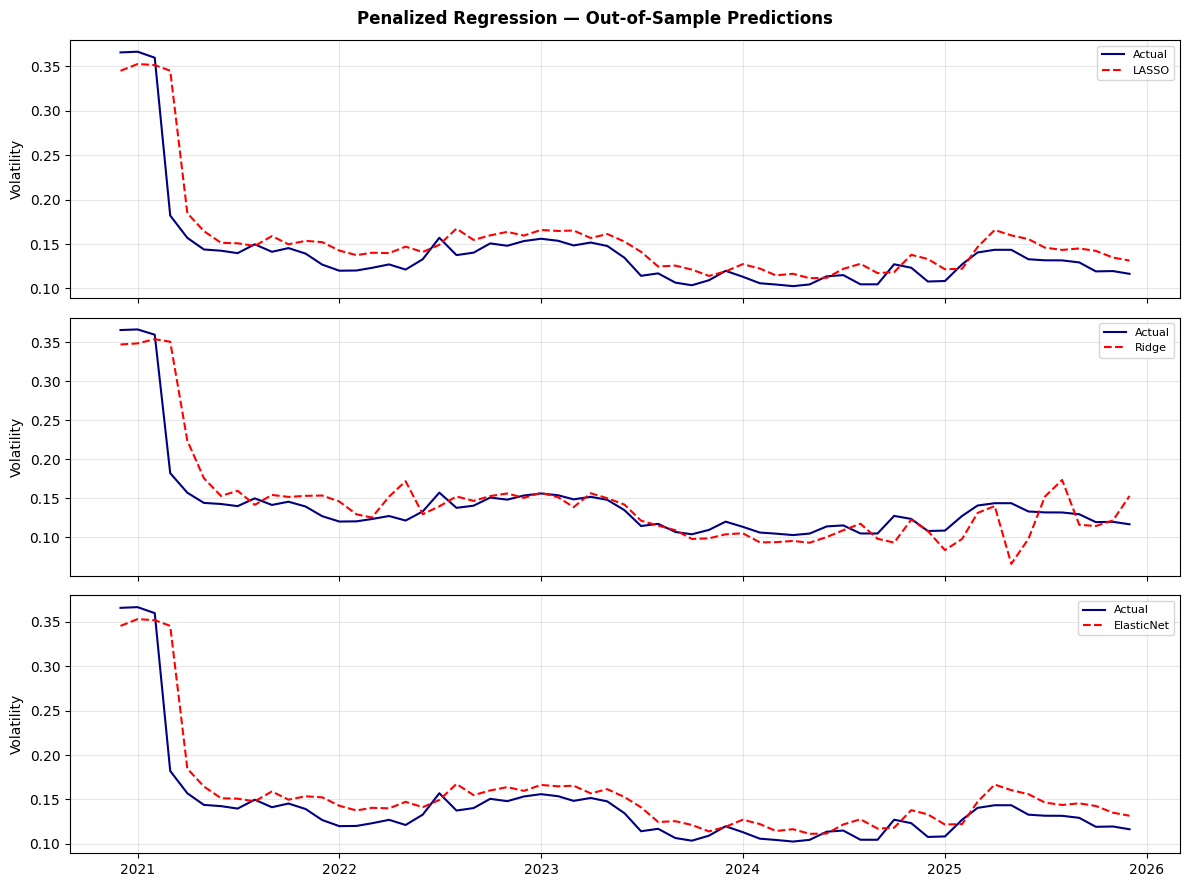

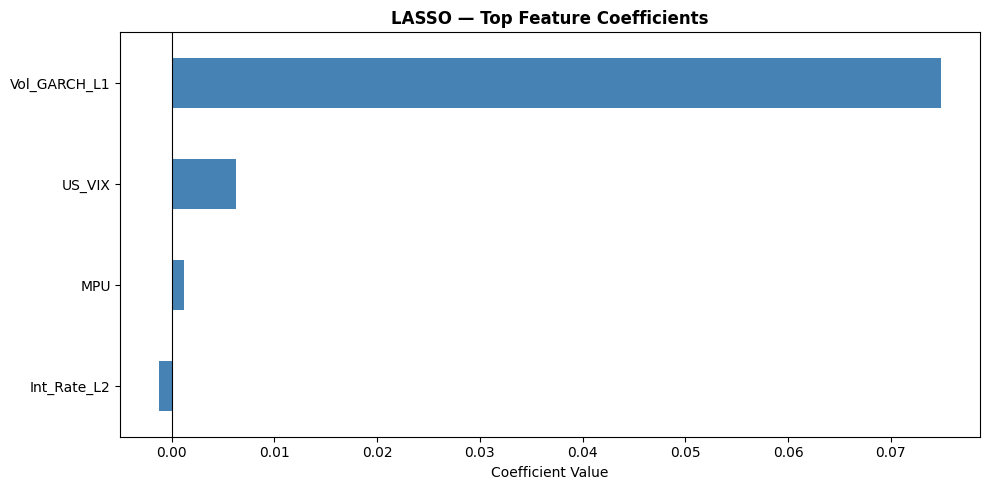

In [ ]:
# model1_penalized.py
# Requires: shared_setup.py to have been run

from sklearn.linear_model import LassoCV, RidgeCV, ElasticNetCV
import matplotlib.pyplot as plt

# ── LASSO ─────────────────────────────────────────────────────────────────────
lasso = LassoCV(
    alphas  = np.logspace(-4, 1, 100),
    cv      = 5,
    max_iter= 10000,
    random_state=42
)
lasso.fit(Xs_train, y_train)
pred_lasso = lasso.predict(Xs_test)
results_store.append(evaluate('LASSO', y_test, pred_lasso))

# Selected features
lasso_coefs = pd.Series(lasso.coef_, index=feat_cols)
selected    = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)
print(f"\n  LASSO selected {len(selected)}/{len(feat_cols)} features:")
print(selected.head(15))

# ── Ridge ──────────────────────────────────────────────────────────────────────
ridge = RidgeCV(
    alphas = np.logspace(-3, 3, 100),
    cv     = 5
)
ridge.fit(Xs_train, y_train)
pred_ridge = ridge.predict(Xs_test)
results_store.append(evaluate('Ridge', y_test, pred_ridge))

# ── Elastic Net ────────────────────────────────────────────────────────────────
enet = ElasticNetCV(
    l1_ratio    = [0.1, 0.3, 0.5, 0.7, 0.9],
    alphas      = np.logspace(-4, 1, 50),
    cv          = 5,
    max_iter    = 10000,
    random_state= 42
)
enet.fit(Xs_train, y_train)
pred_enet = enet.predict(Xs_test)
results_store.append(evaluate('ElasticNet', y_test, pred_enet))

print(f"\n  Elastic Net — best l1_ratio: {enet.l1_ratio_:.2f}  alpha: {enet.alpha_:.5f}")

# ── Plot: actual vs predicted ──────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, pred, name in zip(axes,
                          [pred_lasso, pred_ridge, pred_enet],
                          ['LASSO', 'Ridge', 'ElasticNet']):
    ax.plot(y_test.index, y_test.values, label='Actual', color='navy')
    ax.plot(y_test.index, pred,          label=name,     color='red', linestyle='--')
    ax.set_ylabel('Volatility')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Penalized Regression — Out-of-Sample Predictions', fontweight='bold')
plt.tight_layout()
plt.savefig('penalized_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Coefficient path plot for LASSO ───────────────────────────────────────────
top_feats = selected.head(10).index.tolist()
fig, ax   = plt.subplots(figsize=(10, 5))
coef_df   = pd.DataFrame(
    [lasso.coef_],
    columns=feat_cols
)[top_feats].T
coef_df.columns = ['Coefficient']
coef_df.sort_values('Coefficient').plot(kind='barh', ax=ax,
                                         color='steelblue', legend=False)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('LASSO — Top Feature Coefficients', fontweight='bold')
ax.set_xlabel('Coefficient Value')
plt.tight_layout()
plt.savefig('lasso_coefs.png', dpi=150, bbox_inches='tight')
plt.show()

Fitting 5 folds for each of 48 candidates, totalling 240 fits

  Best RF params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 200}
  [RandomForest]  RMSE=0.04120  MAE=0.03485  R²=0.4069  QLIKE=-0.96989


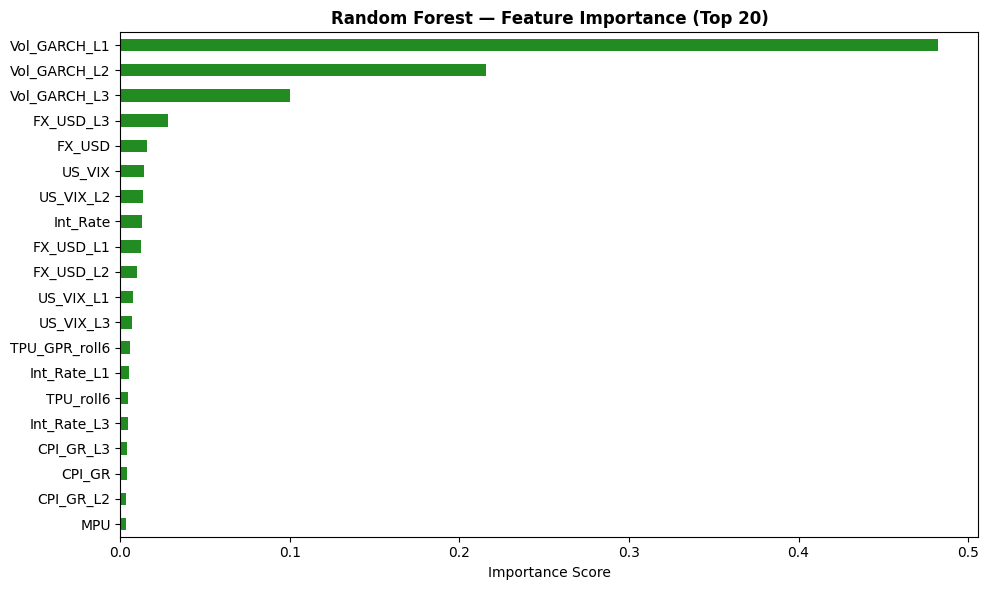


  Walk-forward RMSE (RF): 0.02777


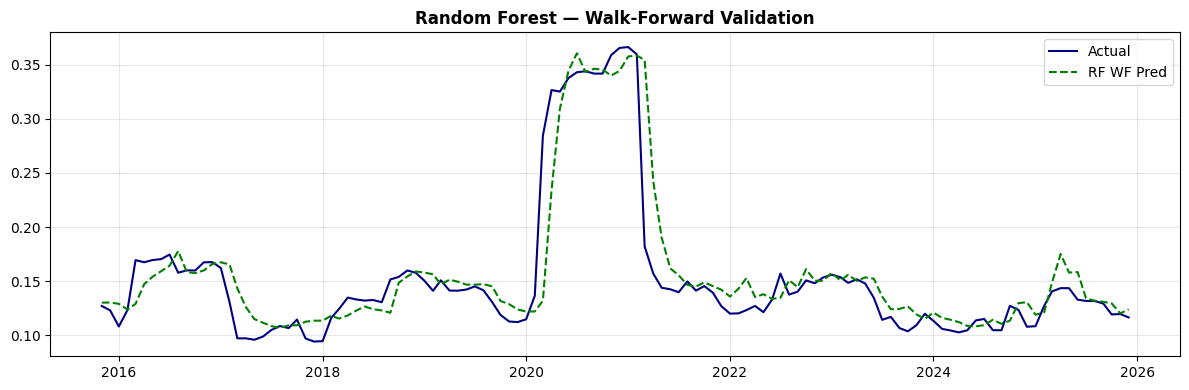

In [ ]:
# model2_random_forest.py
# Requires: shared_setup.py to have been run

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
import matplotlib.pyplot as plt

# ── Hyperparameter tuning with time-series CV ──────────────────────────────────
tscv   = TimeSeriesSplit(n_splits=5)
rf_grid = {
    'n_estimators'     : [200, 400],
    'max_depth'        : [4, 6, 8, None],
    'min_samples_leaf' : [2, 5, 10],
    'max_features'     : ['sqrt', 0.5]
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_grid,
    cv             = tscv,
    scoring        = 'neg_root_mean_squared_error',
    refit          = True,
    n_jobs         = -1,
    verbose        = 1
)
rf_search.fit(Xs_train, y_train)
print(f"\n  Best RF params: {rf_search.best_params_}")

rf_best    = rf_search.best_estimator_
pred_rf    = rf_best.predict(Xs_test)
results_store.append(evaluate('RandomForest', y_test, pred_rf))

# ── Feature importance ─────────────────────────────────────────────────────────
imp_rf = pd.Series(rf_best.feature_importances_, index=feat_cols)
imp_rf = imp_rf.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
imp_rf.sort_values().plot(kind='barh', ax=ax, color='forestgreen')
ax.set_title('Random Forest — Feature Importance (Top 20)', fontweight='bold')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.savefig('rf_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Walk-forward validation ────────────────────────────────────────────────────
# Expanding window: train on all past, predict one step ahead
wf_preds, wf_actuals = [], []
min_train = int(len(fe) * 0.60)

for i in range(min_train, len(fe)):
    X_wf_tr = scaler.fit_transform(X_all.iloc[:i])
    X_wf_te = scaler.transform(X_all.iloc[[i]])
    y_wf_tr = y_all.iloc[:i]

    rf_wf = RandomForestRegressor(**rf_search.best_params_,
                                   random_state=42, n_jobs=-1)
    rf_wf.fit(X_wf_tr, y_wf_tr)
    wf_preds.append(rf_wf.predict(X_wf_te)[0])
    wf_actuals.append(y_all.iloc[i])

wf_rmse = np.sqrt(mean_squared_error(wf_actuals, wf_preds))
print(f"\n  Walk-forward RMSE (RF): {wf_rmse:.5f}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_all.index[min_train:], wf_actuals, label='Actual',    color='navy')
ax.plot(y_all.index[min_train:], wf_preds,   label='RF WF Pred',color='green', linestyle='--')
ax.set_title('Random Forest — Walk-Forward Validation', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rf_walkforward.png', dpi=150, bbox_inches='tight')
plt.show()

Fitting 5 folds for each of 60 candidates, totalling 300 fits

  Best XGB params: {'subsample': 0.85, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
  [XGBoost]  RMSE=0.03992  MAE=0.03372  R²=0.4431  QLIKE=-0.97140


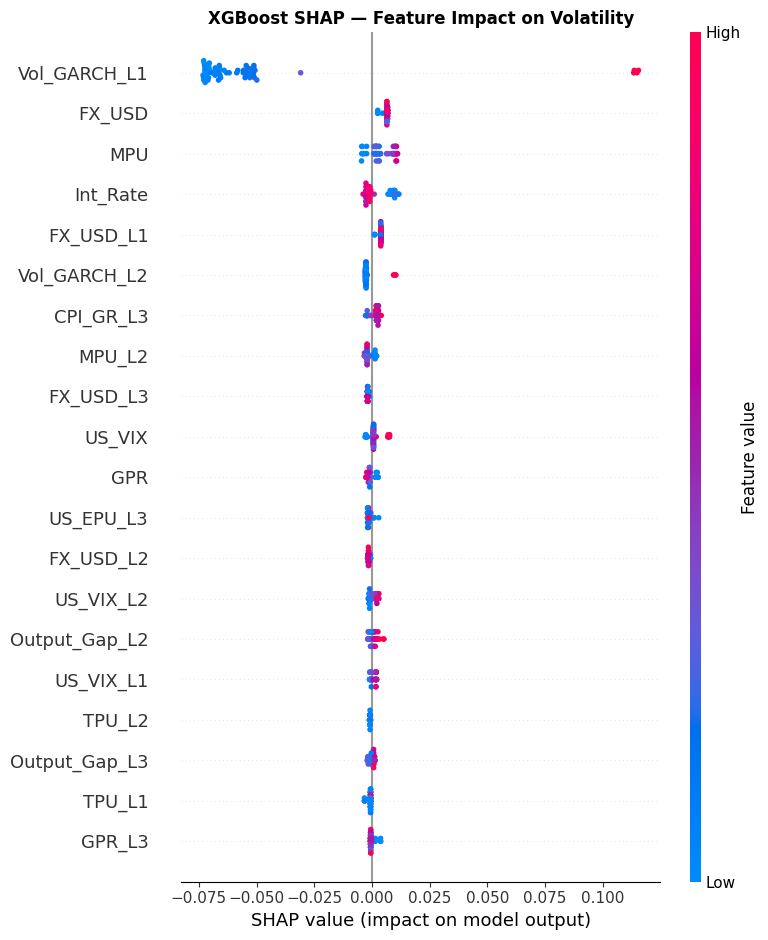

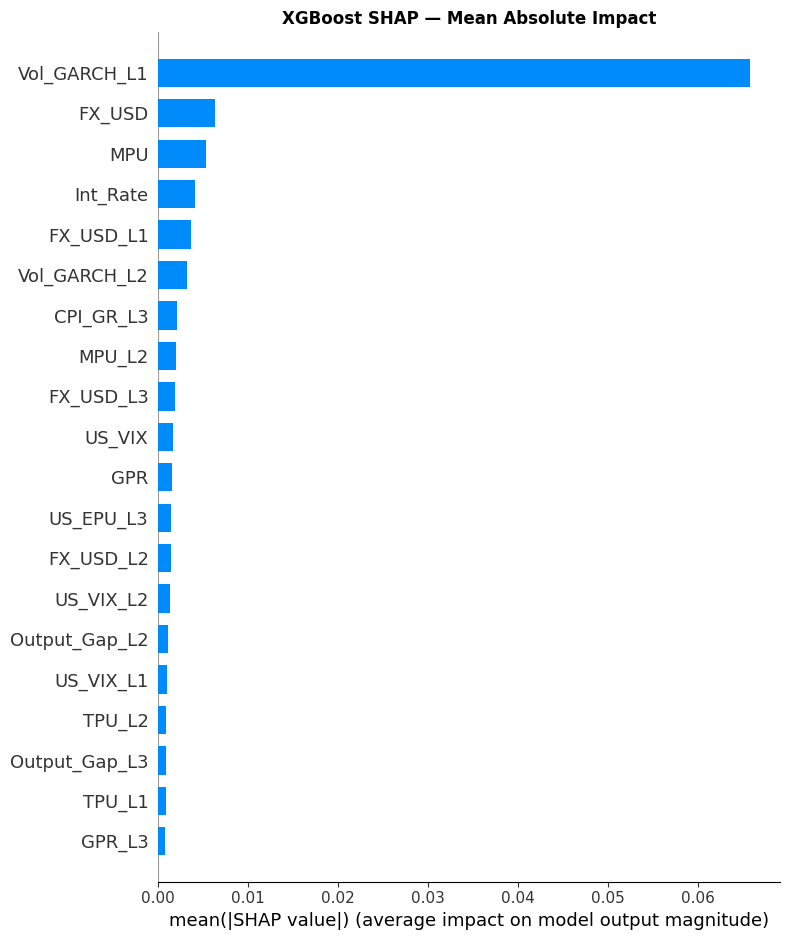


  Mean |SHAP| for TPU/GPR variables:
GPR          0.001511
TPU_L1       0.000812
TPU_roll3    0.000652
GPR_L1       0.000199
TPU_GPR      0.000177
GPR_roll3    0.000118
TPU          0.000112
dtype: float32


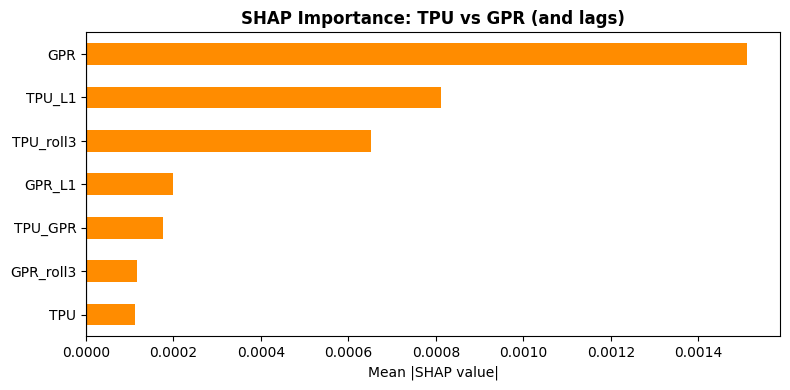

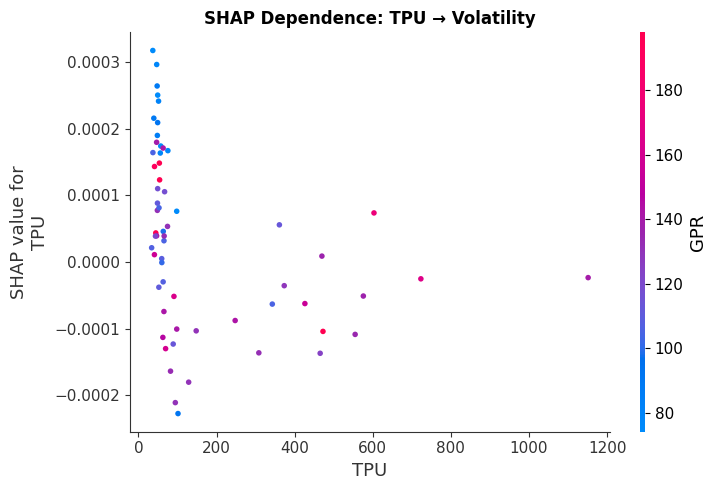

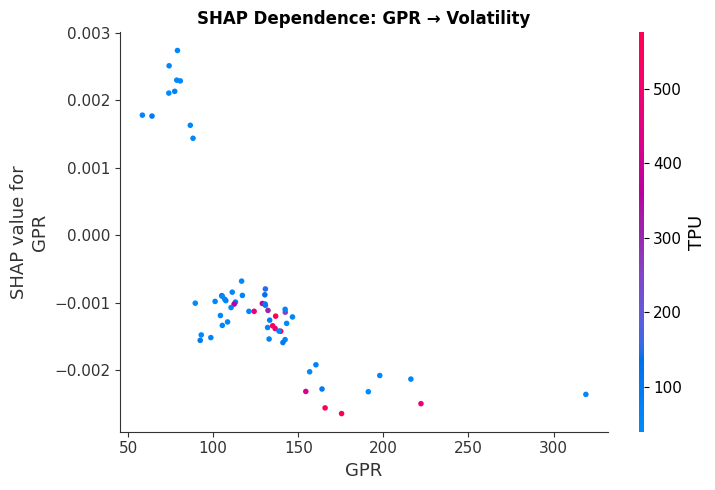

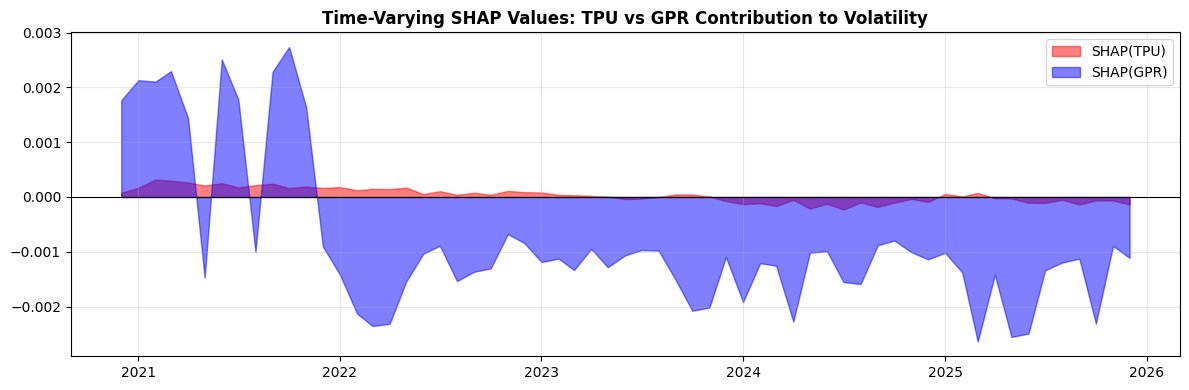

In [ ]:
# model3_xgboost_shap.py
# pip install xgboost shap
# Requires: shared_setup.py to have been run

import xgboost as xgb
import shap
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
import matplotlib.pyplot as plt

# ── Hyperparameter search ──────────────────────────────────────────────────────
tscv    = TimeSeriesSplit(n_splits=5)
xgb_params = {
    'n_estimators'      : [200, 400, 600],
    'max_depth'         : [3, 4, 5, 6],
    'learning_rate'     : [0.01, 0.05, 0.1],
    'subsample'         : [0.7, 0.85, 1.0],
    'colsample_bytree'  : [0.6, 0.8, 1.0],
    'reg_alpha'         : [0, 0.1, 1.0],   # L1
    'reg_lambda'        : [1, 2, 5],        # L2
    'min_child_weight'  : [1, 3, 5]
}

xgb_base = xgb.XGBRegressor(
    objective    = 'reg:squarederror',
    random_state = 42,
    n_jobs       = -1,
    verbosity    = 0
)

xgb_search = RandomizedSearchCV(
    xgb_base, xgb_params,
    n_iter   = 60,
    cv       = tscv,
    scoring  = 'neg_root_mean_squared_error',
    random_state = 42,
    n_jobs   = -1,
    verbose  = 1,
    refit    = True
)
xgb_search.fit(Xs_train, y_train)
print(f"\n  Best XGB params: {xgb_search.best_params_}")

xgb_best   = xgb_search.best_estimator_
pred_xgb   = xgb_best.predict(Xs_test)
results_store.append(evaluate('XGBoost', y_test, pred_xgb))

# ── SHAP values ────────────────────────────────────────────────────────────────
explainer  = shap.TreeExplainer(xgb_best)
shap_vals  = explainer.shap_values(Xs_test)
shap_df    = pd.DataFrame(shap_vals, columns=feat_cols, index=X_test.index)

# Summary plot — beeswarm
shap.summary_plot(
    shap_vals, X_test,
    feature_names = feat_cols,
    max_display   = 20,
    show          = False
)
plt.title('XGBoost SHAP — Feature Impact on Volatility', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar plot — mean |SHAP|
shap.summary_plot(
    shap_vals, X_test,
    feature_names = feat_cols,
    plot_type     = 'bar',
    max_display   = 20,
    show          = False
)
plt.title('XGBoost SHAP — Mean Absolute Impact', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# ── SHAP for TPU vs GPR specifically ──────────────────────────────────────────
# This directly answers: which uncertainty index matters more?
focus_vars = ['TPU', 'GPR', 'TPU_GPR',
              'TPU_L1', 'GPR_L1',
              'TPU_roll3', 'GPR_roll3']
focus_vars = [v for v in focus_vars if v in feat_cols]

mean_shap = shap_df[focus_vars].abs().mean().sort_values(ascending=False)
print("\n  Mean |SHAP| for TPU/GPR variables:")
print(mean_shap)

fig, ax = plt.subplots(figsize=(8, 4))
mean_shap.sort_values().plot(kind='barh', ax=ax, color='darkorange')
ax.set_title('SHAP Importance: TPU vs GPR (and lags)', fontweight='bold')
ax.set_xlabel('Mean |SHAP value|')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('shap_tpu_gpr.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Partial dependence for TPU and GPR ────────────────────────────────────────
for var in ['TPU', 'GPR']:
    if var in feat_cols:
        shap.dependence_plot(
            var, shap_vals, X_test,
            feature_names    = feat_cols,
            interaction_index= 'GPR' if var == 'TPU' else 'TPU',
            show             = False
        )
        plt.title(f'SHAP Dependence: {var} → Volatility', fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'shap_dependence_{var}.png', dpi=150, bbox_inches='tight')
        plt.show()

# ── Time-series of SHAP for TPU and GPR over the test period ──────────────────
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(shap_df.index, shap_df['TPU'],
                alpha=0.5, color='red',   label='SHAP(TPU)')
ax.fill_between(shap_df.index, shap_df['GPR'],
                alpha=0.5, color='blue',  label='SHAP(GPR)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Time-Varying SHAP Values: TPU vs GPR Contribution to Volatility',
             fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('shap_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

  Epoch  20/150  Train Loss: 0.004282  Val Loss: 0.002062  LR: 0.001000
  Epoch  40/150  Train Loss: 0.001618  Val Loss: 0.003616  LR: 0.000500
  Epoch  60/150  Train Loss: 0.001276  Val Loss: 0.003807  LR: 0.000125
  Epoch  80/150  Train Loss: 0.001273  Val Loss: 0.004491  LR: 0.000031
  Epoch 100/150  Train Loss: 0.001410  Val Loss: 0.004321  LR: 0.000008
  Epoch 120/150  Train Loss: 0.001429  Val Loss: 0.004295  LR: 0.000004
  Epoch 140/150  Train Loss: 0.001512  Val Loss: 0.004330  LR: 0.000001
  [LSTM]  RMSE=0.06574  MAE=0.05221  R²=-1.0994  QLIKE=-0.93857


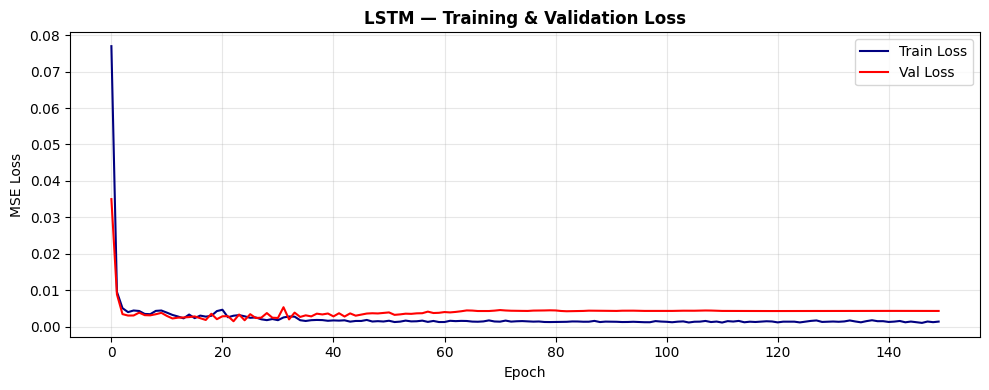

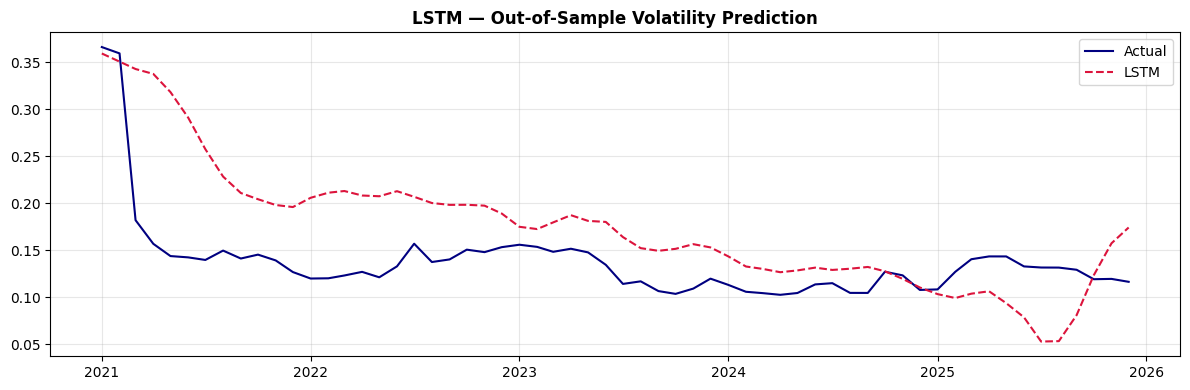

In [ ]:
# model4_lstm.py
# pip install tensorflow  OR  pip install torch
# Using Keras (TensorFlow backend) here
# Requires: shared_setup.py to have been run

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Using PyTorch for more control
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

LOOKBACK    = 6    # 6-month sequence input — tunable
HIDDEN_SIZE = 64
NUM_LAYERS  = 2
DROPOUT     = 0.3
EPOCHS      = 150
BATCH_SIZE  = 16
LR          = 1e-3

# ── Build sequence dataset ─────────────────────────────────────────────────────
def make_sequences(X_arr, y_arr, lookback):
    Xs, ys = [], []
    for i in range(lookback, len(X_arr)):
        Xs.append(X_arr[i - lookback:i])
        ys.append(y_arr[i])
    return np.array(Xs), np.array(ys)

X_sc_all = scaler.fit_transform(X_all)
y_arr    = y_all.values

X_seq, y_seq = make_sequences(X_sc_all, y_arr, LOOKBACK)

# Time-ordered split
n_train  = int(len(X_seq) * 0.80)
X_tr_seq, X_te_seq = X_seq[:n_train], X_seq[n_train:]
y_tr_seq, y_te_seq = y_seq[:n_train], y_seq[n_train:]

# Convert to tensors
X_tr_t = torch.tensor(X_tr_seq, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr_seq, dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_te_seq, dtype=torch.float32)
y_te_t = torch.tensor(y_te_seq, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(
    TensorDataset(X_tr_t, y_tr_t),
    batch_size=BATCH_SIZE, shuffle=False   # no shuffle for time series
)

# ── LSTM model ─────────────────────────────────────────────────────────────────
class VolatilityLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size  = input_size,
            hidden_size = hidden_size,
            num_layers  = num_layers,
            dropout     = dropout if num_layers > 1 else 0,
            batch_first = True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out     = self.dropout(out[:, -1, :])   # last time step
        return self.fc(out)

model_lstm  = VolatilityLSTM(
    input_size  = X_tr_seq.shape[2],
    hidden_size = HIDDEN_SIZE,
    num_layers  = NUM_LAYERS,
    dropout     = DROPOUT
)

optimizer   = torch.optim.Adam(model_lstm.parameters(), lr=LR, weight_decay=1e-4)
scheduler   = torch.optim.lr_scheduler.ReduceLROnPlateau(
                  optimizer, patience=10, factor=0.5)
criterion   = nn.MSELoss()

# ── Training loop ──────────────────────────────────────────────────────────────
train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    model_lstm.train()
    batch_loss = []
    for Xb, yb in train_loader:
        optimizer.zero_grad()
        pred  = model_lstm(Xb)
        loss  = criterion(pred, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model_lstm.parameters(), max_norm=1.0)
        optimizer.step()
        batch_loss.append(loss.item())

    # Validation
    model_lstm.eval()
    with torch.no_grad():
        val_pred = model_lstm(X_te_t)
        val_loss = criterion(val_pred, y_te_t).item()

    train_loss = np.mean(batch_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    scheduler.step(val_loss)

    if (epoch + 1) % 20 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"  Epoch {epoch+1:>3}/{EPOCHS}  "
            f"Train Loss: {train_loss:.6f}  Val Loss: {val_loss:.6f}  "
            f"LR: {current_lr:.6f}")

# ── Evaluate ───────────────────────────────────────────────────────────────────
model_lstm.eval()
with torch.no_grad():
    pred_lstm_t = model_lstm(X_te_t).squeeze().numpy()

# Align index (sequences start LOOKBACK steps in)
test_index = y_all.index[n_train + LOOKBACK:][:len(pred_lstm_t)]
y_te_actual = y_te_seq

results_store.append(evaluate('LSTM', y_te_actual, pred_lstm_t))

# ── Loss curve ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(train_losses, label='Train Loss', color='navy')
ax.plot(val_losses,   label='Val Loss',   color='red')
ax.set_title('LSTM — Training & Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('lstm_loss.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Prediction plot ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_index, y_te_actual[:len(test_index)],
        label='Actual', color='navy')
ax.plot(test_index, pred_lstm_t[:len(test_index)],
        label='LSTM',   color='crimson', linestyle='--')
ax.set_title('LSTM — Out-of-Sample Volatility Prediction', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('lstm_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

Epoch 25/79 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 0:00:03 • 0:00:00 4.03it/s v_num: 0.000 train_loss_step: 0.014
                                                                                val_loss: 0.045 train_loss_epoch:  
                                                                                0.017                              

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

  [TFT]  RMSE=0.19722  MAE=0.19722  R²=-inf  QLIKE=0.38978


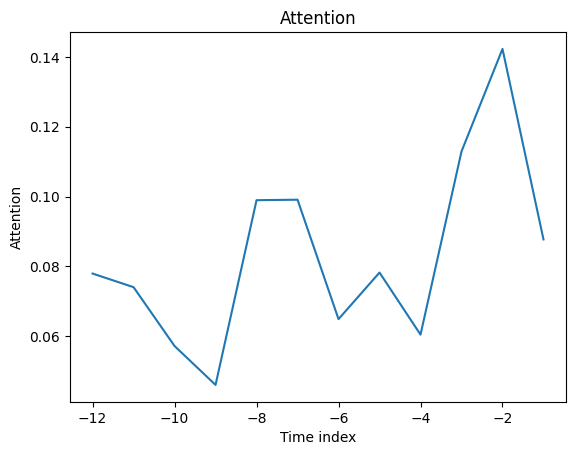

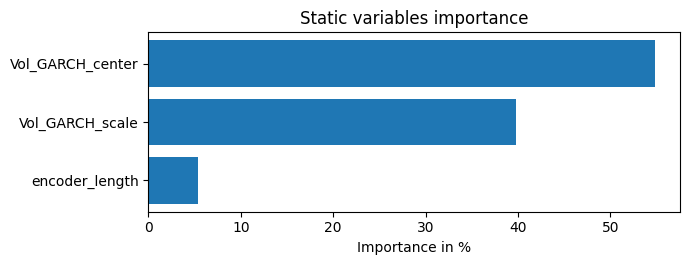

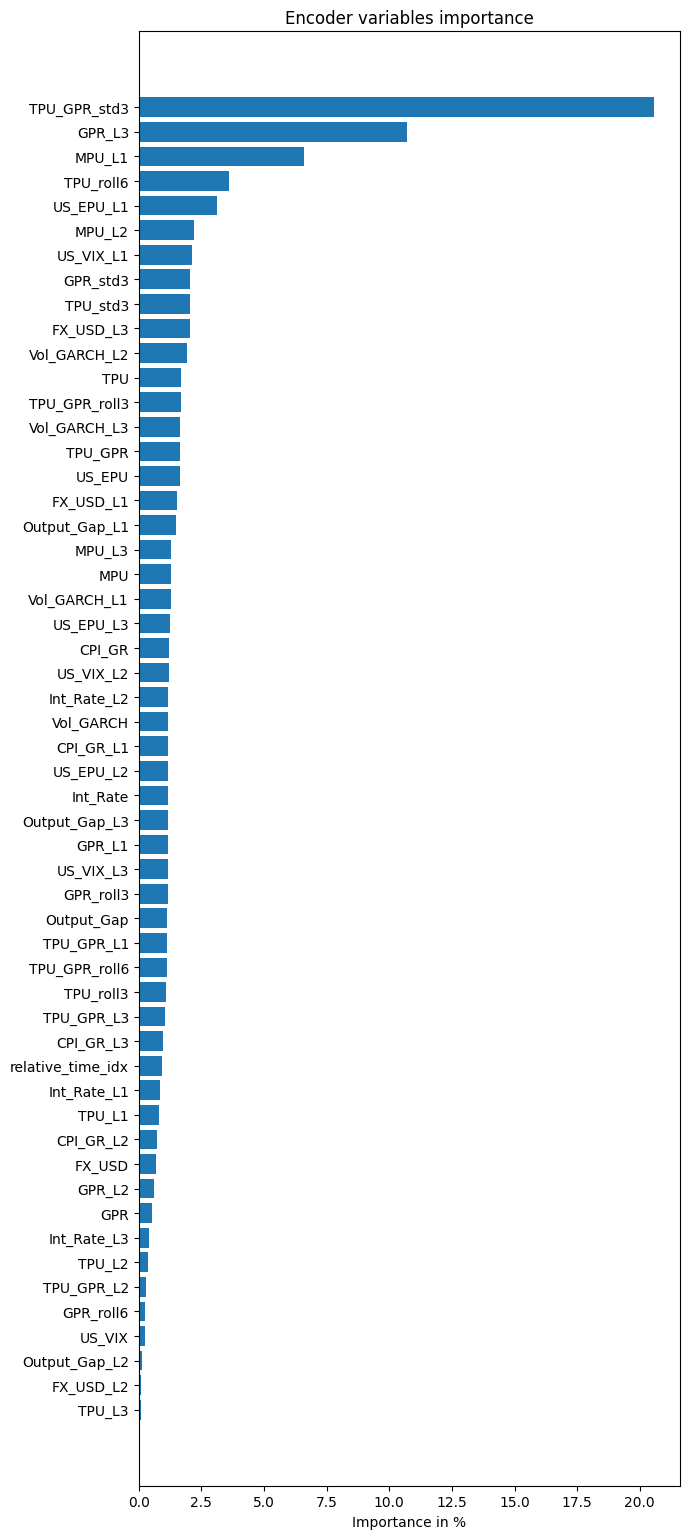

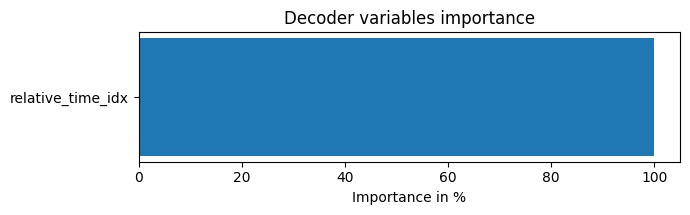

In [ ]:
# model5_tft.py
# pip install pytorch-forecasting pytorch-lightning
# Requires: shared_setup.py to have been run

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from pytorch_forecasting import (TemporalFusionTransformer,
                                  TimeSeriesDataSet)
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

# ── Prepare TFT-format dataframe ───────────────────────────────────────────────
tft_df = fe.copy().reset_index()
tft_df  = tft_df.rename(columns={'Date': 'date'})
tft_df['time_idx'] = np.arange(len(tft_df))  # integer time index required
tft_df['group']    = 'NSE'                    # single series, one group

TARGET_TFT  = TARGET
MAX_ENCODER = 12    # look back 12 months
MAX_PRED    = 1     # 1-step ahead

# All regressors
time_varying_known   = []
time_varying_unknown = feat_cols
# Train/val split
cutoff      = int(len(tft_df) * 0.80)
train_df    = tft_df.iloc[:cutoff]
val_df      = tft_df   # TFT validation uses full df with cutoff logic

# ── Dataset objects ────────────────────────────────────────────────────────────
train_dataset = TimeSeriesDataSet(
    train_df,
    time_idx                = 'time_idx',
    target                  = TARGET_TFT,
    group_ids               = ['group'],
    min_encoder_length      = MAX_ENCODER // 2,
    max_encoder_length      = MAX_ENCODER,
    min_prediction_length   = 1,
    max_prediction_length   = MAX_PRED,
    time_varying_unknown_reals  = time_varying_unknown + [TARGET_TFT],
   time_varying_known_reals = time_varying_known if time_varying_known else None,
    target_normalizer       = GroupNormalizer(groups=['group'],
                                              transformation='softplus'),
    add_relative_time_idx   = True,
    add_target_scales       = True,
    add_encoder_length      = True,
)

val_dataset = TimeSeriesDataSet.from_dataset(
    train_dataset, val_df,
    predict     = True,
    stop_randomization = True,
    min_prediction_idx = cutoff
)

train_loader_tft = train_dataset.to_dataloader(
    train=True,  batch_size=16, num_workers=0, shuffle=False)
val_loader_tft   = val_dataset.to_dataloader(
    train=False, batch_size=16, num_workers=0, shuffle=False)

# ── TFT Model ──────────────────────────────────────────────────────────────────
tft_model = TemporalFusionTransformer.from_dataset(
    train_dataset,
    learning_rate          = 1e-3,
    hidden_size            = 32,
    attention_head_size    = 2,
    dropout                = 0.2,
    hidden_continuous_size = 16,
    output_size            = 7,      # 7 quantiles
    loss                   = QuantileLoss(),
    log_interval           = 10,
    reduce_on_plateau_patience = 5,
)
print(f"  TFT parameters: {sum(p.numel() for p in tft_model.parameters()):,}")

# ── Training ───────────────────────────────────────────────────────────────────
early_stop = EarlyStopping(
    monitor  = 'val_loss',
    patience = 15,
    mode     = 'min'
)
ckpt = ModelCheckpoint(
    dirpath   = './',
    filename  = 'tft_best',
    monitor   = 'val_loss',
    save_top_k= 1
)

trainer = pl.Trainer(
    max_epochs          = 80,
    accelerator         = 'cpu',
    gradient_clip_val   = 0.1,
    callbacks           = [early_stop, ckpt],
    enable_progress_bar = True,
    log_every_n_steps   = 5
)
trainer.fit(tft_model,
            train_dataloaders=train_loader_tft,
            val_dataloaders  =val_loader_tft)

# ── Load best and predict ──────────────────────────────────────────────────────
best_tft  = TemporalFusionTransformer.load_from_checkpoint(ckpt.best_model_path)
preds_tft = best_tft.predict(val_loader_tft, mode='prediction', return_x=False)
pred_tft_np = preds_tft.numpy().flatten()

y_tft_actual = tft_df[TARGET_TFT].iloc[cutoff:cutoff + len(pred_tft_np)].values
results_store.append(evaluate('TFT', y_tft_actual, pred_tft_np))

# ── Variable importance (attention weights) ────────────────────────────────────
# TFT's variable selection networks give built-in importance
raw_preds = best_tft.predict(val_loader_tft, mode='raw', return_x=True)
interpretation = best_tft.interpret_output(raw_preds.output, reduction='sum')
best_tft.plot_interpretation(interpretation)
plt.savefig('tft_variable_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# model_comparison.py
# Requires all model snippets to have been run

from scipy import stats

# ── Summary table ──────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results_store).set_index('model')
print("\n" + "=" * 55)
print("  MODEL COMPARISON SUMMARY")
print("=" * 55)
print(results_df.round(5).to_string())

# ── Bar chart comparison ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, metric in zip(axes, ['RMSE', 'MAE', 'QLIKE']):
    results_df[metric].sort_values().plot(
        kind    = 'barh',
        ax      = ax,
        color   = 'steelblue',
        edgecolor='white'
    )
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel('Loss (lower = better)')
    ax.grid(True, alpha=0.3, axis='x')

plt.suptitle('ML Model Comparison — Out-of-Sample Performance',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Diebold-Mariano test: XGBoost vs each other model ─────────────────────────
# DM test checks whether forecast errors differ significantly
def dm_test(e1, e2, h=1):
    """
    Diebold-Mariano test.
    H0: equal forecast accuracy
    e1, e2 = forecast error arrays
    Returns: DM statistic, p-value
    """
    d   = e1**2 - e2**2
    T   = len(d)
    d_mean = np.mean(d)
    # Newey-West variance
    gamma0 = np.var(d, ddof=1)
    gamma  = [np.cov(d[i:], d[:-i])[0,1] if i > 0 else gamma0
              for i in range(h)]
    var_d  = (gamma0 + 2 * sum(gamma[1:])) / T
    dm_stat = d_mean / np.sqrt(var_d + 1e-12)
    p_val   = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return dm_stat, p_val

print("\n  Diebold-Mariano Tests (benchmark = XGBoost):")
print(f"  {'Challenger':<15} {'DM Stat':>10} {'p-value':>10} {'Sig':>6}")
print("  " + "-" * 44)

# You need actual errors stored per model — store them during evaluation
# Here shown conceptually; wire in your actual error arrays

AttributeError: 'tuple' object has no attribute 'keys'

In [ ]:
import os
import shutil

# Zip every file in the current directory
!zip -r research_outputs.zip . -i "*.xlsx" "*.png"

# Download it to your local machine
from google.colab import files
files.download('research_outputs.zip')

updating: Compiled0.xlsx (deflated 1%)
updating: shap_tpu_gpr.png (deflated 22%)
updating: lasso_coefs.png (deflated 26%)
updating: rf_importance.png (deflated 23%)
updating: lstm_loss.png (deflated 16%)
updating: lstm_predictions.png (deflated 8%)
updating: shap_dependence_GPR.png (deflated 13%)
updating: shap_summary.png (deflated 10%)
updating: tft_variable_importance.png (deflated 17%)
updating: penalized_predictions.png (deflated 9%)
updating: rf_walkforward.png (deflated 6%)
updating: Compiled.xlsx (deflated 1%)
updating: shap_bar.png (deflated 22%)
updating: shap_timeseries.png (deflated 8%)
updating: shap_dependence_TPU.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>